Initializing and training the network...
Epoch [100/5000], Convergence Loss: 108.1349
Epoch [200/5000], Convergence Loss: 96.4654
Epoch [300/5000], Convergence Loss: 59.2262
Epoch [400/5000], Convergence Loss: 55.0909
Epoch [500/5000], Convergence Loss: 38.1026
Epoch [600/5000], Convergence Loss: 39.6510
Epoch [700/5000], Convergence Loss: 26.2561
Epoch [800/5000], Convergence Loss: 29.3598
Epoch [900/5000], Convergence Loss: 40.9956
Epoch [1000/5000], Convergence Loss: 24.7080
Epoch [1100/5000], Convergence Loss: 18.1193
Epoch [1200/5000], Convergence Loss: 20.3083
Epoch [1300/5000], Convergence Loss: 16.2526
Epoch [1400/5000], Convergence Loss: 24.8567
Epoch [1500/5000], Convergence Loss: 18.9959
Epoch [1600/5000], Convergence Loss: 17.5085
Epoch [1700/5000], Convergence Loss: 16.2798
Epoch [1800/5000], Convergence Loss: 17.5697
Epoch [1900/5000], Convergence Loss: 15.6181
Epoch [2000/5000], Convergence Loss: 9.5649
Epoch [2100/5000], Convergence Loss: 13.0146
Epoch [2200/5000], Conv

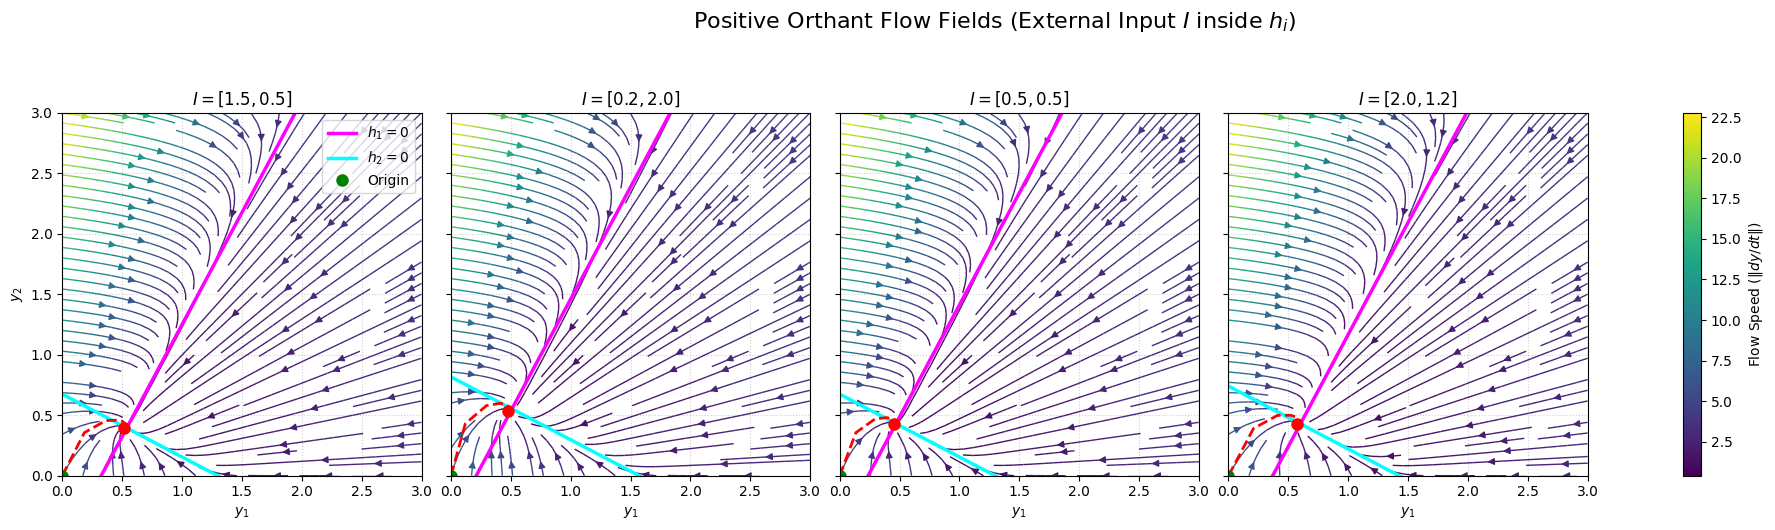

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- 1. Model Definition ---
class BalancedDynamicalSystem(nn.Module):
    def __init__(self, beta=1.0):
        super(BalancedDynamicalSystem, self).__init__()
        self.beta = beta

        # 2D System: W is 2x2, b is 2
        self.W = nn.Parameter(torch.randn(2, 2) * 0.1)
        self.b = nn.Parameter(torch.zeros(2))

    def softplus(self, h):
        return torch.nn.functional.softplus(h, beta=self.beta)

    def forward_ode(self, y, I):
        # External input I is now explicitly part of the h_i definition
        h = torch.matmul(y, self.W.t()) + self.b + I

        # dy/dt = -y + f(h)
        dydt = -y + self.softplus(h)
        return dydt, h

# --- 2. Training Phase ---
print("Initializing and training the network...")
model = BalancedDynamicalSystem(beta=2.0).to(device)
optimizer = optim.Adam(model.parameters(), lr=0.01)

dt = 0.05
time_steps = 100
batch_size = 64
epochs = 5000

model.train()
for epoch in range(epochs):
    optimizer.zero_grad()

    # Generate batch of random external inputs (simulating diverse steady environments)
    I_ext = torch.randn(batch_size, 2, device=device).unsqueeze(1).repeat(1, time_steps, 1) * 2.0

    # Initial state at the origin
    y = torch.zeros(batch_size, 2, device=device)
    total_loss = 0.0

    for t in range(time_steps):
        I_t = I_ext[:, t, :]
        dydt, h = model.forward_ode(y, I_t)
        y = y + dydt * dt

        # Penalize h deviance heavily at later time steps to force rapid convergence
        time_weight = float(t) / time_steps
        total_loss += time_weight * torch.mean(h**2)

    total_loss.backward()
    optimizer.step()

    if (epoch + 1) % 100 == 0:
        print(f"Epoch [{epoch+1}/{epochs}], Convergence Loss: {total_loss.item():.4f}")

# --- 3. Plotting Phase ---
print("\nGenerating the phase portraits...")
model.eval()

fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharex=True, sharey=True)
fig.suptitle("Positive Orthant Flow Fields (External Input $I$ inside $h_i$)", fontsize=16, y=1.05)

# Setup coordinate grid for positive orthant
y1_range = np.linspace(0, 3, 30)
y2_range = np.linspace(0, 3, 30)
Y1, Y2 = np.meshgrid(y1_range, y2_range)
grid_tensor = torch.tensor(np.c_[Y1.ravel(), Y2.ravel()], dtype=torch.float32).to(device)

# Extract learned structural parameters
W = model.W.detach().cpu().numpy()
b = model.b.detach().cpu().numpy()

# Test across 4 distinct static external inputs
external_inputs = [
    torch.tensor([1.5, 0.5], device=device),
    torch.tensor([0.2, 2.0], device=device),
    torch.tensor([0.5, 0.5], device=device),
    torch.tensor([2.0, 1.2], device=device)
]

for idx, I_val in enumerate(external_inputs):
    ax = axes[idx]
    I_tensor = I_val.unsqueeze(0).repeat(grid_tensor.shape[0], 1)

    # Generate flow fields
    with torch.no_grad():
        dydt, _ = model.forward_ode(grid_tensor, I_tensor)

    U = dydt[:, 0].detach().cpu().numpy().reshape(Y1.shape)
    V = dydt[:, 1].detach().cpu().numpy().reshape(Y1.shape)

    speed = np.sqrt(U**2 + V**2)
    strm = ax.streamplot(Y1, Y2, U, V, color=speed, cmap='viridis', linewidth=1, density=1.2)

    # --- Dynamic h_i = 0 Nullcline Calculations ---
    # Equation: W_i1*y1 + W_i2*y2 + b_i + I_i = 0  =>  y2 = -(W_i1*y1 + b_i + I_i) / W_i2
    I_np = I_val.cpu().numpy()
    h1_line_y2 = -(W[0, 0] * y1_range + b[0] + I_np[0]) / W[0, 1]
    h2_line_y2 = -(W[1, 0] * y1_range + b[1] + I_np[1]) / W[1, 1]

    ax.plot(y1_range, h1_line_y2, color='magenta', lw=2.5, label='$h_1 = 0$')
    ax.plot(y1_range, h2_line_y2, color='cyan', lw=2.5, label='$h_2 = 0$')

    # --- Simulate Sample Trajectory from Origin ---
    y_traj = [torch.tensor([[0.0, 0.0]], device=device)]
    for _ in range(120):
        dydt_t, _ = model.forward_ode(y_traj[-1], I_val.unsqueeze(0))
        y_traj.append(y_traj[-1] + dydt_t * dt)

    traj_np = torch.cat(y_traj).detach().cpu().numpy()
    ax.plot(traj_np[:, 0], traj_np[:, 1], color='red', lw=2, ls='--')
    ax.plot(0, 0, 'go', markersize=8, label='Origin')
    ax.plot(traj_np[-1, 0], traj_np[-1, 1], 'ro', markersize=8)

    # Aesthetics
    ax.set_title(f"$I = [{I_np[0]:.1f}, {I_np[1]:.1f}]$")
    ax.set_xlabel("$y_1$")
    ax.set_xlim([0, 3])
    ax.set_ylim([0, 3])
    if idx == 0:
        ax.set_ylabel("$y_2$")
        ax.legend(loc='upper right')
    ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
fig.colorbar(strm.lines, ax=axes.ravel().tolist(), label='Flow Speed ($\|dy/dt\|$)')
plt.show()

Training the network to become balanced...
Training complete. Generating the joint plot rows...


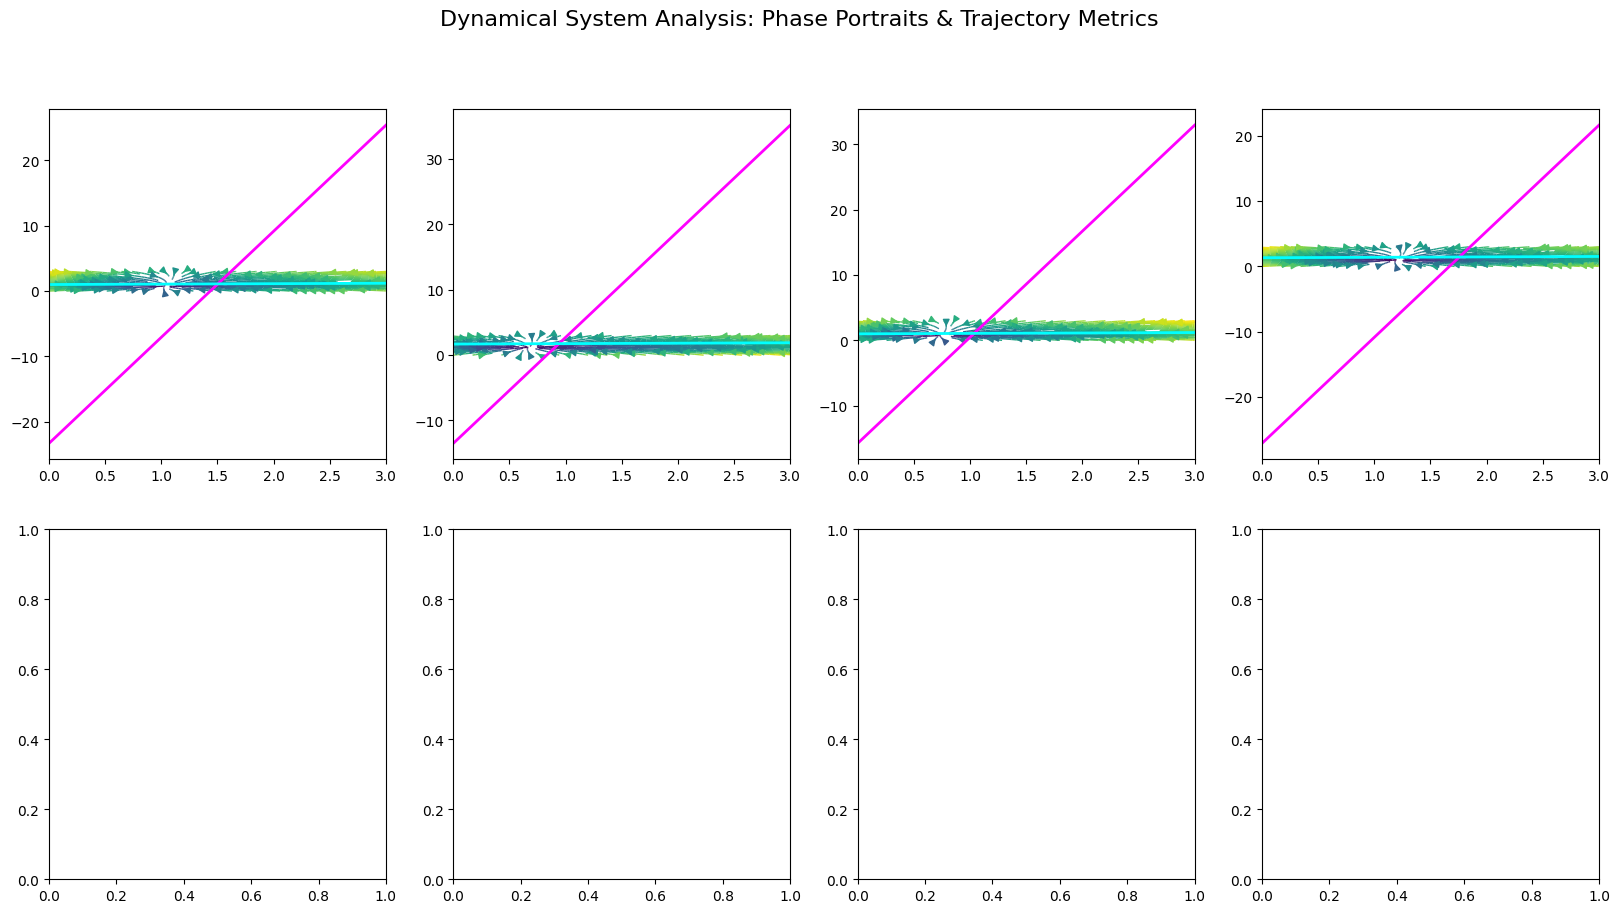

In [22]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- 1. The Trained Balanced Network Class ---
class BalancedDynamicalSystem(nn.Module):
    def __init__(self, beta=2.0):
        super(BalancedDynamicalSystem, self).__init__()
        self.beta = beta

        # 2D System: W is 2x2, b is 2
        self.W = nn.Parameter(torch.randn(2, 2) * 0.1)
        self.b = nn.Parameter(torch.zeros(2))

    def softplus(self, h):
        return torch.nn.functional.softplus(h, beta=self.beta)

    def softplus_second_derivative(self, h):
        f_prime = torch.sigmoid(self.beta * h)
        return self.beta * f_prime * (1.0 - f_prime)

    def forward_ode(self, y, I):
        h = torch.matmul(y, self.W.t()) + self.b + I
        dydt = -y + self.softplus(h)
        return dydt, h

# --- 2. Training Phase ---
print("Training the network to become balanced...")
model = BalancedDynamicalSystem(beta=2.0).to(device)
optimizer = optim.Adam(model.parameters(), lr=0.01)

train_dt = 0.05
train_steps = 100
batch_size = 64

model.train()
for epoch in range(400):
    optimizer.zero_grad()
    I_ext = torch.randn(batch_size, 2, device=device).unsqueeze(1).repeat(1, train_steps, 1) * 2.0
    y = torch.zeros(batch_size, 2, device=device)
    total_loss = 0.0

    for t in range(train_steps):
        I_t = I_ext[:, t, :]
        dydt, h = model.forward_ode(y, I_t)
        y = y + dydt * train_dt
        time_weight = float(t) / train_steps
        total_loss += time_weight * torch.mean(h**2)

    total_loss.backward()
    optimizer.step()

print("Training complete. Generating the joint plot rows...")
model.eval()

# --- 3. Joint Visualization Setup ---
# 2 Rows of 4 subplots
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
fig.suptitle("Dynamical System Analysis: Phase Portraits & Trajectory Metrics", fontsize=16, y=0.98)

# Coordinates for phase portraits (Row 1)
y1_range = np.linspace(0, 3, 30)
y2_range = np.linspace(0, 3, 30)
Y1, Y2 = np.meshgrid(y1_range, y2_range)
grid_tensor = torch.tensor(np.c_[Y1.ravel(), Y2.ravel()], dtype=torch.float32).to(device)

# Simulation parameters for trajectories (Row 2)
sim_dt = 0.02
time_steps = 150
t_axis = np.linspace(0, time_steps * sim_dt, time_steps)

W = model.W.detach().cpu().numpy()
b = model.b.detach().cpu().numpy()

# 4 Distinct external inputs
external_inputs = [
    torch.tensor([1.5, 0.5], device=device),
    torch.tensor([0.2, 2.0], device=device),
    torch.tensor([0.5, 0.5], device=device),
    torch.tensor([2.0, 1.2], device=device)
]

for idx, I_val in enumerate(external_inputs):
    # ------------------ ROW 1: Phase Portraits ------------------
    ax_top = axes[0, idx]
    I_tensor = I_val.unsqueeze(0).repeat(grid_tensor.shape[0], 1)

    with torch.no_grad():
        dydt, _ = model.forward_ode(grid_tensor, I_tensor)

    U = dydt[:, 0].detach().cpu().numpy().reshape(Y1.shape)
    V = dydt[:, 1].detach().cpu().numpy().reshape(Y1.shape)
    speed = np.sqrt(U**2 + V**2)
    strm = ax_top.streamplot(Y1, Y2, U, V, color=speed, cmap='viridis', linewidth=1, density=1.2)

    # Calculate nullclines
    I_np = I_val.cpu().numpy()
    h1_line_y2 = -(W[0, 0] * y1_range + b[0] + I_np[0]) / W[0, 1]
    h2_line_y2 = -(W[1, 0] * y1_range + b[1] + I_np[1]) / W[1, 1]

    ax_top.plot(y1_range, h1_line_y2, color='magenta', lw=2, label='$h_1 = 0$')
    ax_top.plot(y1_range, h2_line_y2, color='cyan', lw=2, label='$h_2 = 0$')

    # ------------------ Simulate Trajectory from Origin ------------------
    y_current = torch.tensor([[0.0, 0.0]], device=device)
    traj_list = []
    h_history = []
    f_double_prime_history = []

    for t in range(time_steps):
        with torch.no_grad():
            dydt_t, h_t = model.forward_ode(y_current, I_val.unsqueeze(0))
            f_pp_t = model.softplus_second_derivative(h_t)

            traj_list.append(y_current.cpu().numpy()[0])
            h_history.append(h_t.cpu().numpy()[0])

In [86]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class RNN(torch.nn.Module):
    def __init__(self, n, input_dim, beta, bias):
        super(RNN, self).__init__()
        self.n = n
        self.input_dim = input_dim
        self.beta = beta
        self.bias = bias
        self.activation = torch.nn.Softplus(beta=self.beta)
        self.recurrent_layer = nn.Linear(self.n, self.n, bias=True)
        self.recurrent_layer.bias.data.normal_(mean=self.bias, std=0)
        self.recurrent_layer.bias.requires_grad = True
        self.input_layer = nn.Linear(self.input_dim, self.n, bias=False)
        self.input_layer.weight.requires_grad = False
        self.alpha =.1
    def forward(self, u, dt, steps):
        batch_size = u.shape[0]
        states = torch.zeros(batch_size, 1, self.n, device=device)
        for i in range(steps - 1):
            state_new = (1 - self.alpha * dt) * states[:, i, :] + self.alpha *dt * (
                self.activation(self.recurrent_layer(states[:, i, :]) + self.input_layer(u)))
            states = torch.cat((states, state_new.unsqueeze_(1)), 1)
        return states

# --- 2. Training Phase with Varying Initial States & Inputs ---
print("Initializing and training the network with diverse conditions...")
net = RNN(n = 2, input_dim =1, beta=2.0,bias = 1).to(device)
optimizer = optim.Adam(net.parameters(), lr=0.001)

dt = 0.05
steps = 100
batch_size = 64
epochs = 2000

u = torch.FloatTensor(np.linspace(-1, 1, 10)).to(device)
neuron_balance_weights = [1.0, 1.0]
balance_weights_tensor = torch.tensor(neuron_balance_weights, dtype=torch.float32, device=device)

model.train()
for epoch in range(epochs):
    optimizer.zero_grad()
    x = net(u.unsqueeze(1),dt,steps)
    h = net.recurrent_layer(x)+net.input_layer(u.unsqueeze(1)).unsqueeze(1).expand(-1, steps, -1)
    # y = torch.rand(batch_size, 2, device=device) * 3.0
    # total_loss = 0.0
    neuron_balance = torch.mean( h**2, dim=(0,1))
    loss = torch.mean(neuron_balance)
    loss.backward()
    optimizer.step()
    if epoch % 10 == 0:
        print(loss.item())



Initializing and training the network with diverse conditions...
1.0574818849563599
1.032019853591919
1.0071723461151123
0.9829916954040527
0.9595019817352295
0.9367055892944336
0.9145908951759338
0.8931391835212708
0.8723292350769043
0.852138876914978
0.8325467109680176
0.8135316371917725
0.7950736284255981
0.7771533131599426
0.7597522735595703
0.742853045463562
0.7264387011528015
0.710493266582489
0.6950013041496277
0.6799479722976685
0.6653191447257996
0.6511012315750122
0.6372812986373901
0.6238467693328857
0.610785722732544
0.5980866551399231
0.5857384204864502
0.5737304091453552
0.5620524883270264
0.5506947040557861
0.5396476984024048
0.5289023518562317
0.5184497833251953
0.5082815885543823
0.49838966131210327
0.48876601457595825
0.479403018951416
0.4702935218811035
0.4614304304122925
0.45280689001083374
0.44441622495651245
0.43625208735466003
0.42830830812454224
0.4205789566040039
0.41305816173553467
0.40574055910110474
0.39862045645713806
0.3916926980018616
0.3849523067474365
0

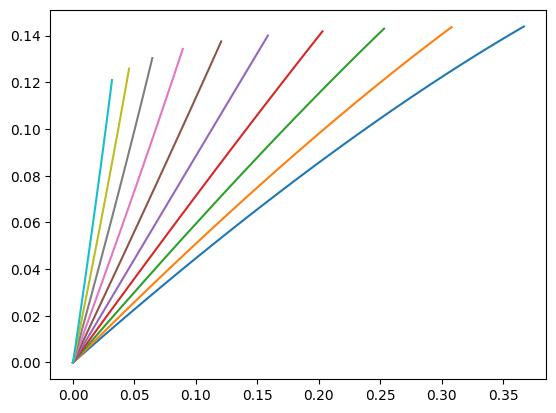

In [87]:
plt.figure()
for i in range(10):
    plt.plot( x[i,:,0].detach(), x[i,:,1].detach())

In [82]:
x

tensor([[[0.0000, 0.0000],
         [0.0020, 0.0020],
         [0.0039, 0.0039],
         ...,
         [0.1377, 0.1380],
         [0.1387, 0.1390],
         [0.1397, 0.1399]],

        [[0.0000, 0.0000],
         [0.0020, 0.0020],
         [0.0039, 0.0039],
         ...,
         [0.1377, 0.1380],
         [0.1387, 0.1390],
         [0.1397, 0.1399]],

        [[0.0000, 0.0000],
         [0.0020, 0.0020],
         [0.0039, 0.0039],
         ...,
         [0.1377, 0.1380],
         [0.1387, 0.1390],
         [0.1397, 0.1399]],

        ...,

        [[0.0000, 0.0000],
         [0.0020, 0.0020],
         [0.0039, 0.0039],
         ...,
         [0.1377, 0.1380],
         [0.1387, 0.1390],
         [0.1397, 0.1399]],

        [[0.0000, 0.0000],
         [0.0020, 0.0020],
         [0.0039, 0.0039],
         ...,
         [0.1377, 0.1380],
         [0.1387, 0.1390],
         [0.1397, 0.1399]],

        [[0.0000, 0.0000],
         [0.0020, 0.0020],
         [0.0039, 0.0039],
         ...,
 